# Workshop 2 - Object detection using web camera
## Name : udhaya s
## Register number : 212225230287

In [3]:
%pip install ultralytics

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached torch-2.15.0-cp311-cp311-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 381.6 kB/s eta 0:00:03
   -------------- ------------------------- 0.5/1.4 MB 381.6 kB/s eta 0:00:03
   ---

In [2]:
model = YOLO("yolov8m.pt")

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


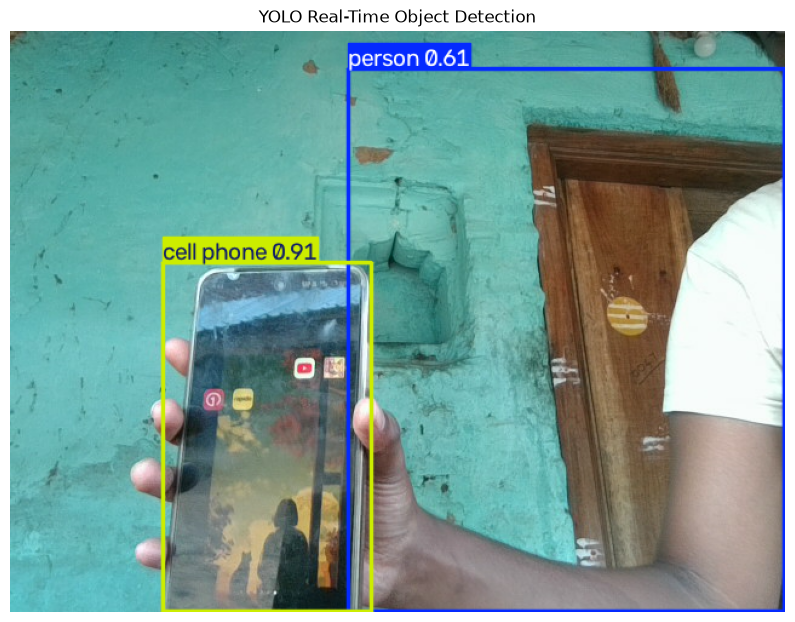

Detection stopped.
Webcam released.
Video saved as YOLO_Detection_Output.mp4


In [3]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
from IPython.display import clear_output

# Load a more accurate YOLO model
model = YOLO("yolov8m.pt")

# Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Could not open webcam.")

else:
    video_writer = None

    try:
        while True:

            ret, frame = cap.read()

            if not ret:
                break

            results = model(
                frame,
                conf=0.60,
                verbose=False
            )

            annotated_frame = results[0].plot()

            # Initialize video writer
            if video_writer is None:
                h, w = annotated_frame.shape[:2]

                video_writer = cv2.VideoWriter(
                    "YOLO_Detection_Output.mp4",
                    cv2.VideoWriter_fourcc(*"mp4v"),
                    20,
                    (w, h)
                )

            # Save detected frame
            video_writer.write(annotated_frame)

            # Display output in Jupyter
            rgb_frame = cv2.cvtColor(
                annotated_frame,
                cv2.COLOR_BGR2RGB
            )

            clear_output(wait=True)

            plt.figure(figsize=(10, 8))
            plt.imshow(rgb_frame)
            plt.title("YOLO Real-Time Object Detection")
            plt.axis("off")
            plt.show()

    except KeyboardInterrupt:
        print("Detection stopped.")

    finally:
        # Release webcam
        cap.release()

        # Release video writer
        if video_writer is not None:
            video_writer.release()

        print("Webcam released.")
        print("Video saved as YOLO_Detection_Output.mp4")